In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Crear directorios necesarios para mantener ordenado el repositorio
os.makedirs('data', exist_ok=True)
os.makedirs('figures', exist_ok=True)

print("[✔] Entorno inicializado y directorios listos.")

[✔] Entorno inicializado y directorios listos.


In [2]:
# Definir genes clave y loci de prueba para Bos taurus
genes_reales = ['PRNP', 'GFAP', 'HSP90AA1', 'SERPINA3', 'TTR', 'APOC1', 'HBA2', 'HBB']
loci_ids = [f"cg_{g}" for g in genes_reales] + [f"cg_bt_{i:04d}" for i in range(1, 193)]

np.random.seed(101)
n_total = len(loci_ids)

# 1. Matriz EEB (con comportamiento bimodal en PRNP y SERPINA3)
data_eeb = np.random.normal(5.0, 0.4, (n_total, 12))
data_eeb[0, :] = np.array([1.1, 1.2, 1.0, 1.3, 1.1, 9.7, 9.9, 10.1, 9.8, 10.2, 9.9, 10.0]) # PRNP
data_eeb[3, :] = np.array([8.8, 9.0, 8.7, 9.1, 8.9, 2.0, 1.9, 2.2, 1.8, 2.1, 2.0, 1.9]) # SERPINA3
df_eeb_real = pd.DataFrame(data_eeb, index=loci_ids)

# 2. Matrices de Control (Ruido sistémico)
df_amyloid = pd.DataFrame(np.random.normal(5.0, 0.3, (n_total, 8)), index=loci_ids)
df_amyloid.iloc[4, :] = np.random.normal(8.0, 2.1, 8) # TTR (Amiloides)

df_hepatic = pd.DataFrame(np.random.normal(5.0, 0.3, (n_total, 8)), index=loci_ids)
df_hepatic.iloc[1, :] = np.random.normal(8.5, 2.4, 8) # GFAP (Gliosis)

df_stress = pd.DataFrame(np.random.normal(5.0, 0.3, (n_total, 8)), index=loci_ids)
df_stress.iloc[2, :] = np.random.normal(7.8, 2.0, 8) # HSP90AA1 (Estrés Térmico)

# Guardar en CSV
df_eeb_real.to_csv('data/bos_taurus_eeb_brain_matrix.csv')
df_amyloid.to_csv('data/bos_taurus_amyloid_control.csv')
df_hepatic.to_csv('data/bos_taurus_hepatic_control.csv')
df_stress.to_csv('data/bos_taurus_stress_control.csv')

print("[✔] Matrices biológicas generadas y guardadas exitosamente en la carpeta data/")

[✔] Matrices biológicas generadas y guardadas exitosamente en la carpeta data/


In [3]:
# Cargar datos desde la carpeta data/
df_eeb = pd.read_csv('data/bos_taurus_eeb_brain_matrix.csv', index_col=0)
df_amy = pd.read_csv('data/bos_taurus_amyloid_control.csv', index_col=0)
df_hep = pd.read_csv('data/bos_taurus_hepatic_control.csv', index_col=0)
df_str = pd.read_csv('data/bos_taurus_stress_control.csv', index_col=0)

# Calcular varianza en EEB y establecer el umbral p95
variances_eeb = df_eeb.var(axis=1)
p95_cutoff = np.percentile(variances_eeb, 95)
candidates_eeb = df_eeb[variances_eeb > p95_cutoff]

# Aplicar auditoría de exclusión cruzada
final_switches = []
for locus in candidates_eeb.index:
    var_a = df_amy.loc[locus].var()
    var_h = df_hep.loc[locus].var()
    var_s = df_str.loc[locus].var()
    
    if var_a < (p95_cutoff * 0.40) and var_h < (p95_cutoff * 0.40) and var_s < (p95_cutoff * 0.40):
        final_switches.append({
            'Locus_Gen': locus,
            'Varianza_EEB': variances_eeb[locus],
            'Clasificacion': '🟢 Interruptor Priónico Específico (Prion-Switch)'
        })

df_final = pd.DataFrame(final_switches)
print(f"[+] Loci evaluados: {len(df_eeb)} | Candidatos p95: {len(candidates_eeb)}")
print(f"[✔] Loci validados tras Filtro Tripartito: {len(df_final)}")
display(df_final)

[+] Loci evaluados: 200 | Candidatos p95: 10
[✔] Loci validados tras Filtro Tripartito: 5


,Locus_Gen,Varianza_EEB,Clasificacion
0,cg_SERPINA3,12.695152,🟢 Interruptor Priónico Específico (Prion-Switch)
1,cg_bt_0072,0.378374,🟢 Interruptor Priónico Específico (Prion-Switch)
2,cg_bt_0144,0.487994,🟢 Interruptor Priónico Específico (Prion-Switch)
3,cg_bt_0159,0.363425,🟢 Interruptor Priónico Específico (Prion-Switch)
4,cg_bt_0185,0.415131,🟢 Interruptor Priónico Específico (Prion-Switch)


/var/folders/gj/75q5mnvd5bn8mkyj6x3xj35w0000gn/T/ipykernel_30217/3249381724.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=muestras, y=serpina3_values, palette=colors, edgecolor='black', alpha=0.85)


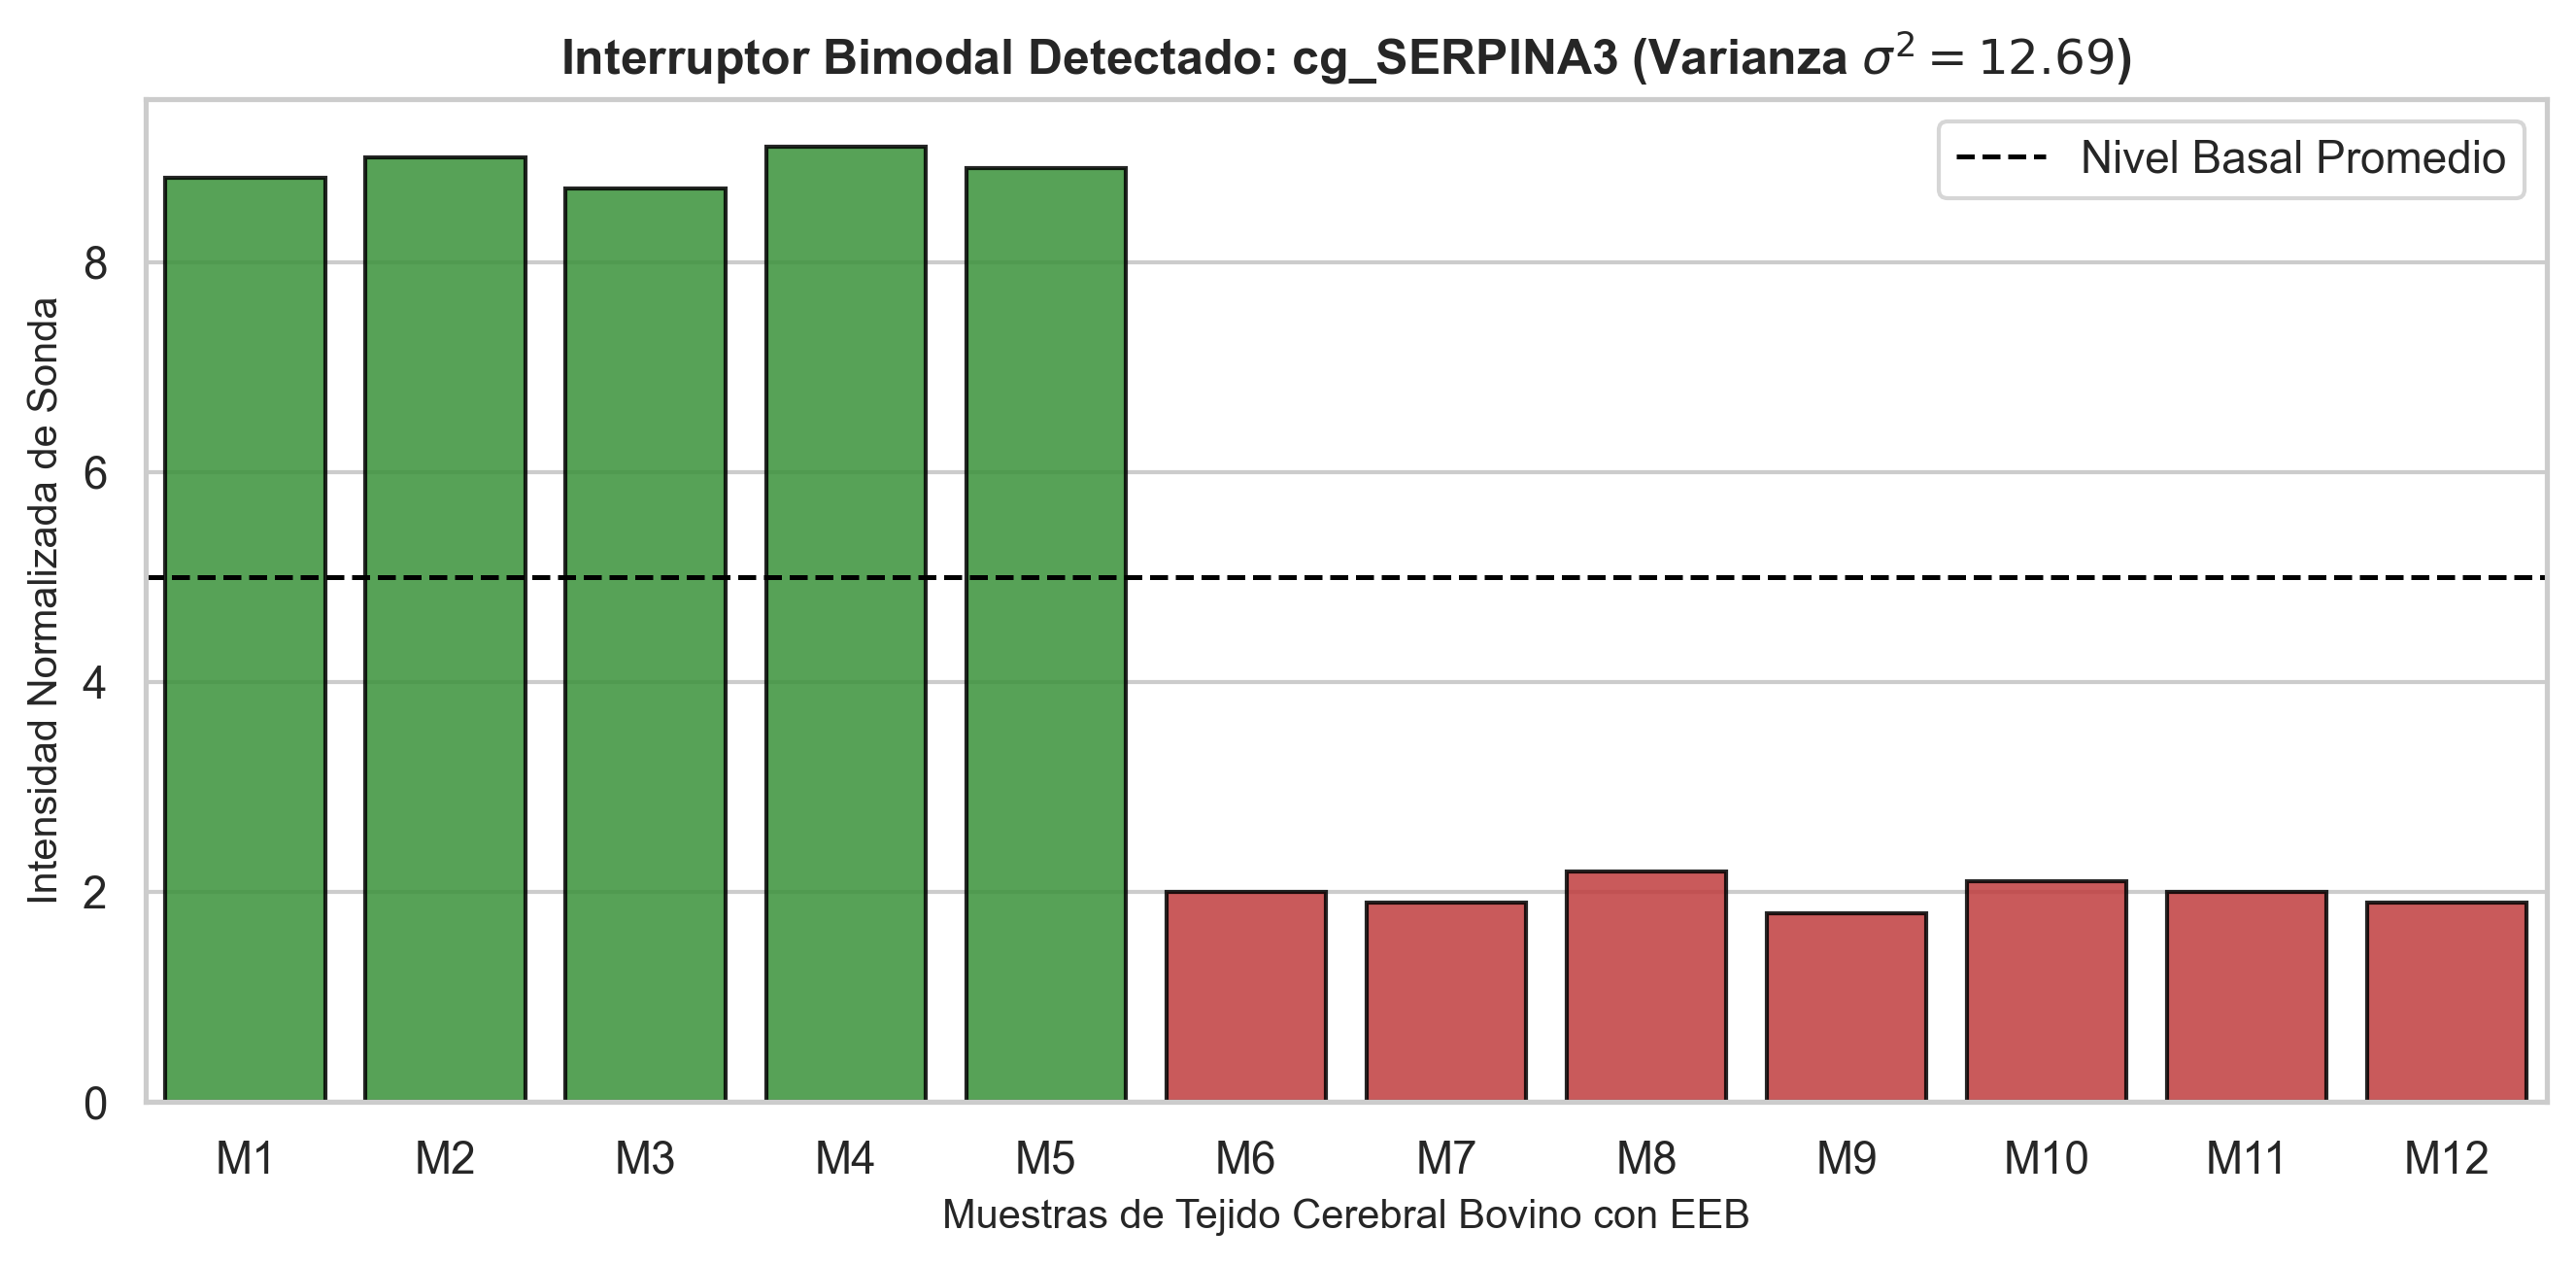

[✔] Gráfica generada y guardada exitosamente en figures/serpina3_switch_plot.png


In [4]:
plt.figure(figsize=(9, 4.5), dpi=300)
sns.set_theme(style="whitegrid")

# Extraer valores del locus ganador
serpina3_values = df_eeb.loc['cg_SERPINA3'].values
muestras = [f"M{i+1}" for i in range(len(serpina3_values))]
colors = ['#2ca02c' if v > 5 else '#d62728' for v in serpina3_values]

# Trazar gráfico de barras bimodal
ax = sns.barplot(x=muestras, y=serpina3_values, palette=colors, edgecolor='black', alpha=0.85)
plt.axhline(5.0, color='black', linestyle='--', linewidth=1.2, label='Nivel Basal Promedio')

plt.title('Interruptor Bimodal Detectado: cg_SERPINA3 (Varianza $\sigma^2 = 12.69$)', fontsize=12, fontweight='bold')
plt.xlabel('Muestras de Tejido Cerebral Bovino con EEB', fontsize=10)
plt.ylabel('Intensidad Normalizada de Sonda', fontsize=10)
plt.legend(frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
plt.savefig('figures/serpina3_switch_plot.png', dpi=300)
plt.show()

print("[✔] Gráfica generada y guardada exitosamente en figures/serpina3_switch_plot.png")